# Conditional KDE baseline

Este notebook organiza el experimento del baseline KDE condicional por calendario. El modelo entrena un Autoencoder sobre `X_train`, lleva los perfiles al espacio latente y ajusta KDEs jerarquicos usando grupos discretos `(mes, dia_semana, es_feriado)` con fallback a grupos menos especificos.

La entrada del experimento sale exclusivamente de `provincias/data/splits/`. No se rehace preprocessing y no se usa `C` completo como condicion del KDE.

## Setup

Importamos las funciones del script del modelo y las utilidades compartidas de evaluacion. El notebook puede ejecutarse desde la raiz del proyecto, desde `provincias/` o desde `provincias/notebooks/`.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import sys

import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd().resolve()
if current_dir.name == "notebooks" and current_dir.parent.name == "provincias":
    provinces_root = current_dir.parent
elif current_dir.name == "provincias":
    provinces_root = current_dir
elif (current_dir / "provincias").exists():
    provinces_root = current_dir / "provincias"
else:
    raise RuntimeError("No se pudo ubicar la carpeta provincias")

src_dir = provinces_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from conditional_kde_baseline import run_conditional_kde_baseline
from model_utils import (
    list_generation_plot_paths,
    load_calendar,
    load_result_table,
    load_x_splits,
    plot_bandwidth_validation,
    plot_metric_by_province,
    plot_training_history,
    print_split_checks,
    validate_x_splits,
)

splits_dir = provinces_root / "data" / "splits"
output_dir = provinces_root / "results" / "conditional_kde_baseline"
splits_dir, output_dir

(PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/data/splits'),
 PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_kde_baseline'))

## Datos de entrada

Cargamos los perfiles diarios ya escalados y verificamos shapes, escala y ausencia de NaNs. Estos chequeos son criticos porque el entrenamiento de PyTorch puede degradarse silenciosamente si hay valores faltantes.

In [2]:
X = load_x_splits(splits_dir)
validate_x_splits(X)
print_split_checks(X)

X_train: shape=(1457, 528), mean=0.0000, std=1.0000, nan_count=0
X_val: shape=(366, 528), mean=0.3081, std=1.1119, nan_count=0
X_test: shape=(485, 528), mean=0.4511, std=1.1791, nan_count=0


In [3]:
calendar_train = load_calendar(splits_dir, "train")
calendar_val = load_calendar(splits_dir, "val")
calendar_test = load_calendar(splits_dir, "test")

display(calendar_train.head())
display(
    pd.DataFrame(
        {
            "split": ["train", "val", "test"],
            "n_days": [len(calendar_train), len(calendar_val), len(calendar_test)],
            "start": [calendar_train["fecha"].min(), calendar_val["fecha"].min(), calendar_test["fecha"].min()],
            "end": [calendar_train["fecha"].max(), calendar_val["fecha"].max(), calendar_test["fecha"].max()],
        }
    )
)

,fecha,mes,dia_semana,es_feriado
0,2019-01-01,1,1,1
1,2019-01-02,1,2,0
2,2019-01-03,1,3,0
3,2019-01-04,1,4,0
4,2019-01-05,1,5,0


,split,n_days,start,end
0,train,1457,2019-01-01,2023-12-31
1,val,366,2024-01-01,2024-12-31
2,test,485,2025-01-01,2026-04-30


## Entrenamiento

El bloque siguiente invoca la funcion principal del experimento. Por defecto queda apagado para evitar reentrenar accidentalmente; si no existen resultados en `provincias/results/conditional_kde_baseline/`, cambiar `RUN_TRAINING` a `True` y ejecutar desde esta celda.

In [4]:
RUN_TRAINING = False

config = SimpleNamespace(
    splits_dir=splits_dir,
    output_dir=output_dir,
    seed=42,
    device="auto",
    latent_dim=16,
    hidden_dim=256,
    epochs=200,
    batch_size=64,
    learning_rate=1e-3,
    weight_decay=1e-5,
    patience=25,
    min_delta=1e-5,
    min_samples=20,
    bandwidths=[0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0],
    n_scenarios=500,
    mmd_max_samples=1000,
    plot_days=4,
)

if RUN_TRAINING:
    output_paths = run_conditional_kde_baseline(config)
    display(output_paths)
else:
    print(f"Usando resultados guardados en {output_dir}")

Usando resultados guardados en /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_kde_baseline


In [5]:
required_files = [
    output_dir / "config.json",
    output_dir / "autoencoder_history.csv",
    output_dir / "bandwidth_validation.csv",
    output_dir / "calendar_group_counts.csv",
    output_dir / "test_fallback_usage.csv",
    output_dir / "reconstruction_metrics.csv",
    output_dir / "metrics_overall.csv",
    output_dir / "metrics_by_province.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Faltan resultados guardados. Cambiar RUN_TRAINING a True y volver a ejecutar. "
        f"Archivos faltantes: {missing_files}"
    )

## Configuracion usada

La configuracion queda guardada para que el resultado sea trazable: dimension latente, grilla de bandwidths, minimo de muestras por grupo y cantidad de escenarios generados por dia.

In [6]:
with open(output_dir / "config.json", "r", encoding="utf-8") as file:
    saved_config = json.load(file)

display(pd.Series(saved_config, name="value").to_frame())

,value
bandwidths,"[0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]"
batch_size,64
best_bandwidth,1.0
data_source,/Users/victoriapersico/Desktop/Ingenieria/Terc...
device,mps
epochs,200
hidden_dim,256
latent_dim,16
learning_rate,0.001
min_samples,20


## Autoencoder

El Autoencoder comprime los 528 valores de cada dia a un espacio latente de baja dimension. El KDE se entrena sobre ese espacio latente, no directamente sobre las dimensiones originales.

,epoch,train_loss,val_loss,best_epoch,best_val_loss
71,72,0.041578,0.102541,51,0.098461
72,73,0.041117,0.103955,51,0.098461
73,74,0.041161,0.101980,51,0.098461
74,75,0.041359,0.106712,51,0.098461
75,76,0.041520,0.102682,51,0.098461


,split,reconstruction_mse_scaled
0,train,0.046317
1,val,0.097052
2,test,0.146215


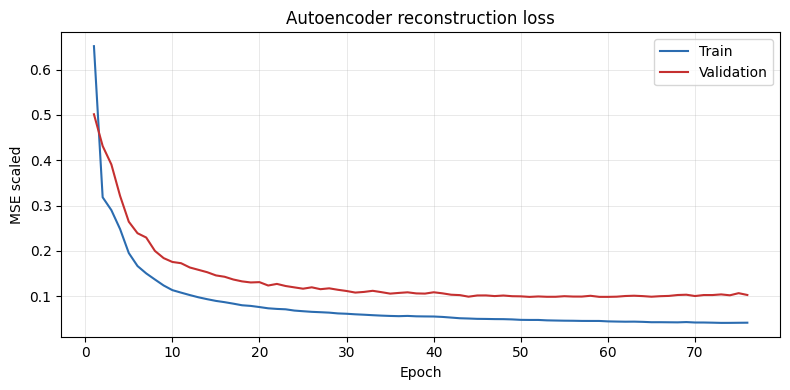

In [7]:
history = load_result_table(output_dir, "autoencoder_history.csv")
reconstruction_metrics = load_result_table(output_dir, "reconstruction_metrics.csv")

display(history.tail())
display(reconstruction_metrics)
plot_training_history(
    history,
    train_column="train_loss",
    val_column="val_loss",
    title="Autoencoder reconstruction loss",
    ylabel="MSE scaled",
)

## Seleccion de bandwidth y fallback

El bandwidth se elige maximizando log-likelihood promedio en validation. Para cada dia se usa el grupo calendario mas especifico disponible y se cae jerarquicamente a `(mes, dia_semana)`, luego `(mes)` y finalmente global.

,bandwidth,val_mean_log_likelihood
0,1.00,-37.242110
1,0.75,-45.372239
2,0.50,-72.525042
3,0.30,-176.602565
4,0.20,-419.653589
5,0.10,-1789.414048
6,0.05,-7301.918945


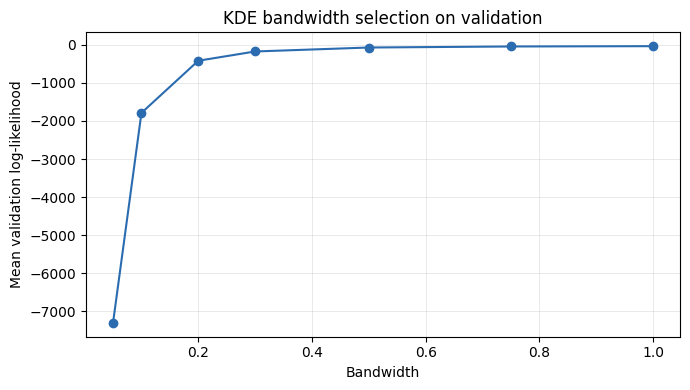

,count,mean,std,min,25%,50%,75%,max
level,,,,,,,,
full,118.0,12.347458,6.846769,1.0,4.0,16.0,17.0,19.0
global,1.0,1457.000000,NaN,1457.0,1457.0,1457.0,1457.0,1457.0
month,12.0,121.416667,3.553701,112.0,120.0,123.0,124.0,124.0
month_weekday,84.0,17.345238,0.813945,16.0,17.0,17.0,18.0,19.0


,n_days
fallback_level,
month,485


In [8]:
bandwidth_results = load_result_table(output_dir, "bandwidth_validation.csv")
group_counts = load_result_table(output_dir, "calendar_group_counts.csv")
fallback_usage = load_result_table(output_dir, "test_fallback_usage.csv")

display(bandwidth_results)
plot_bandwidth_validation(bandwidth_results)
display(group_counts.groupby("level")["n_samples"].describe())
display(fallback_usage["fallback_level"].value_counts().rename_axis("fallback_level").to_frame("n_days"))

## Evaluacion generativa

Las metricas principales se calculan en escala original MWh usando `x_scaler.inverse_transform`. Coverage y sharpness describen la banda probabilistica P5-P95; RMSE compara el perfil real contra el perfil medio generado; MMD compara distribuciones.

In [9]:
overall_metrics = load_result_table(output_dir, "metrics_overall.csv")
province_metrics = load_result_table(output_dir, "metrics_by_province.csv")

display(overall_metrics.T.rename(columns={0: "value"}))
display(province_metrics.sort_values("mean_profile_rmse_mwh").head())
display(province_metrics.sort_values("mean_profile_rmse_mwh", ascending=False).head())

,value
coverage_p5_p95,0.846052
sharpness_p5_p95_mwh,354.677779
mean_profile_rmse_mwh,253.482941
mmd_rbf,0.011177
n_days,485.000000
n_scenarios_per_day,500.000000


,province,coverage_p5_p95,sharpness_p5_p95_mwh,mean_profile_rmse_mwh,mmd_rbf
8,jujuy,0.868385,48.068574,16.898649,0.076894
18,santa_cruz,0.303522,28.370068,18.098379,0.329018
9,la_pampa,0.942440,51.218928,18.791662,0.005707
14,rio_negro,0.932904,68.633384,23.495514,0.022292
13,neuquen,0.757990,63.561934,30.837217,0.121098


,province,coverage_p5_p95,sharpness_p5_p95_mwh,mean_profile_rmse_mwh,mmd_rbf
0,buenos_aires,0.926031,3790.734354,1113.939331,0.007548
19,santa_fe,0.910739,782.978649,245.526443,0.002463
4,cordoba,0.886254,587.415021,212.803040,0.028998
2,chaco,0.858935,262.109549,103.420181,0.020026
3,chubut,0.816237,242.286067,94.213776,0.271199


In [10]:
row = overall_metrics.iloc[0]
print(f"Coverage P5-P95: {row['coverage_p5_p95']:.3f}")
print(f"Sharpness promedio P5-P95: {row['sharpness_p5_p95_mwh']:.2f} MWh")
print(f"RMSE del perfil medio: {row['mean_profile_rmse_mwh']:.2f} MWh")
print(f"MMD RBF: {row['mmd_rbf']:.6f}")

Coverage P5-P95: 0.846
Sharpness promedio P5-P95: 354.68 MWh
RMSE del perfil medio: 253.48 MWh
MMD RBF: 0.011177


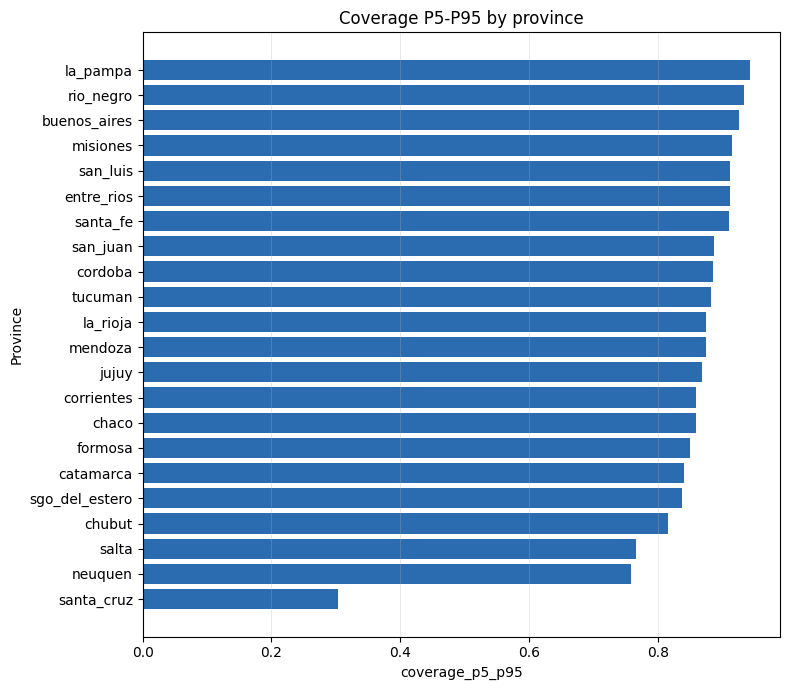

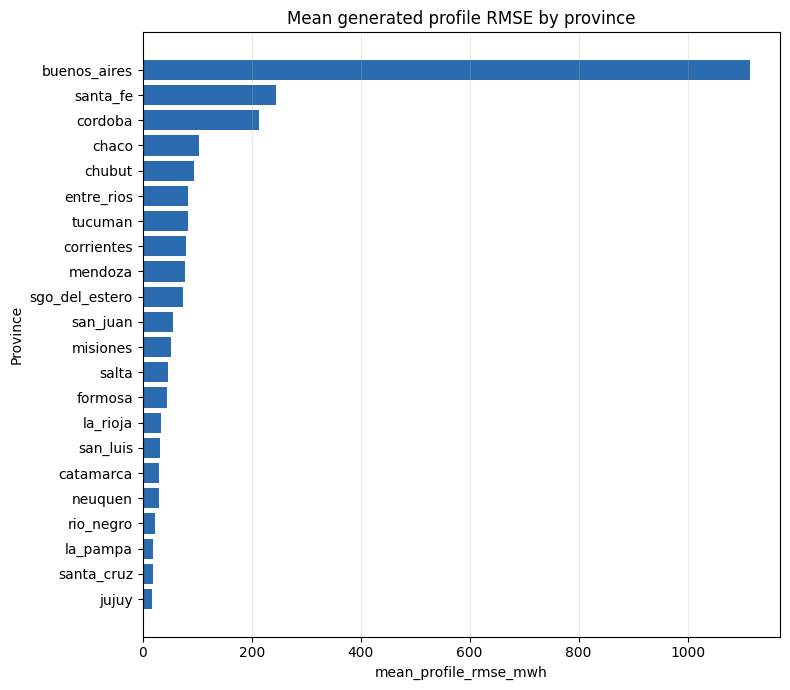

In [11]:
plot_metric_by_province(
    province_metrics,
    metric="coverage_p5_p95",
    title="Coverage P5-P95 by province",
)
plot_metric_by_province(
    province_metrics,
    metric="mean_profile_rmse_mwh",
    title="Mean generated profile RMSE by province",
)

## Perfiles reales vs generados

Estos graficos muestran el perfil horario agregado del sistema para dias representativos de test. La linea roja es el promedio generado y la banda roja corresponde al intervalo P5-P95 de los escenarios.

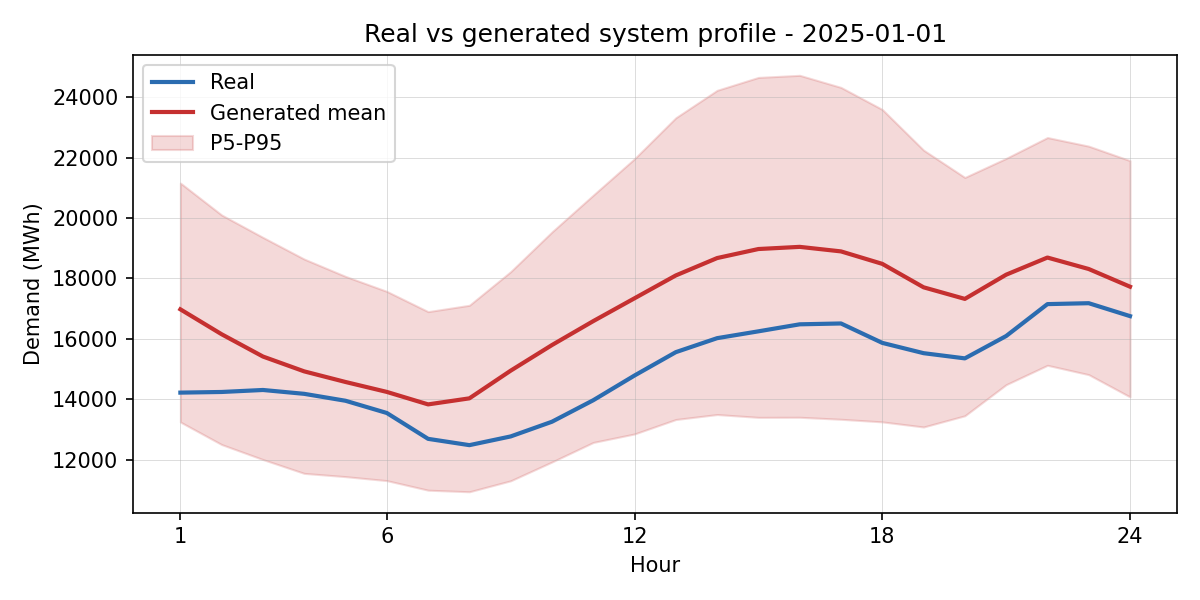

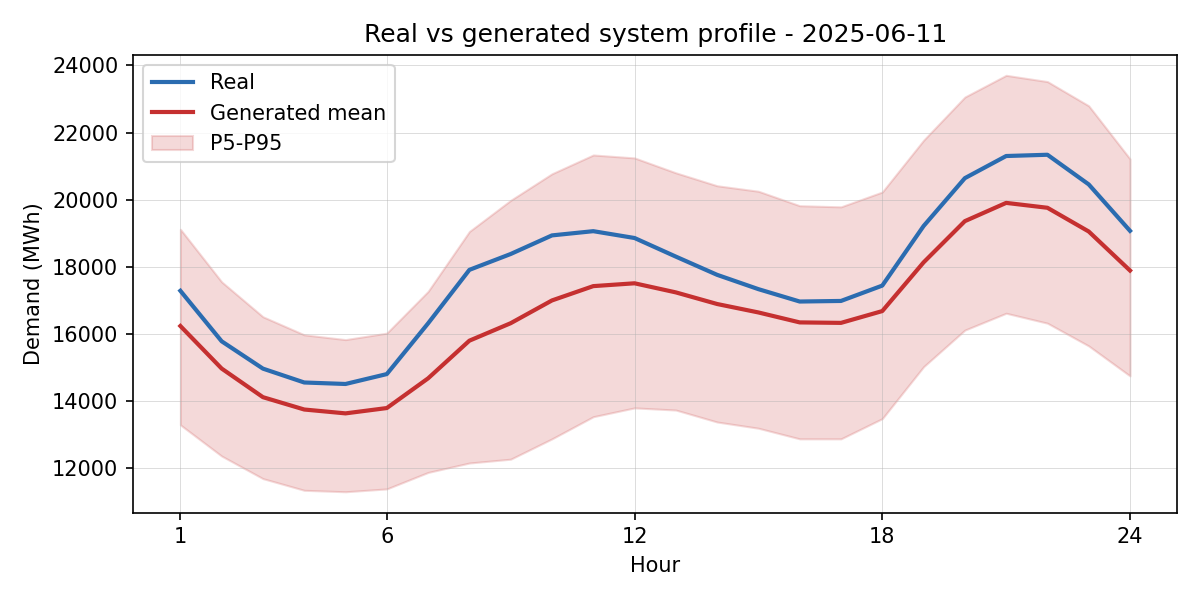

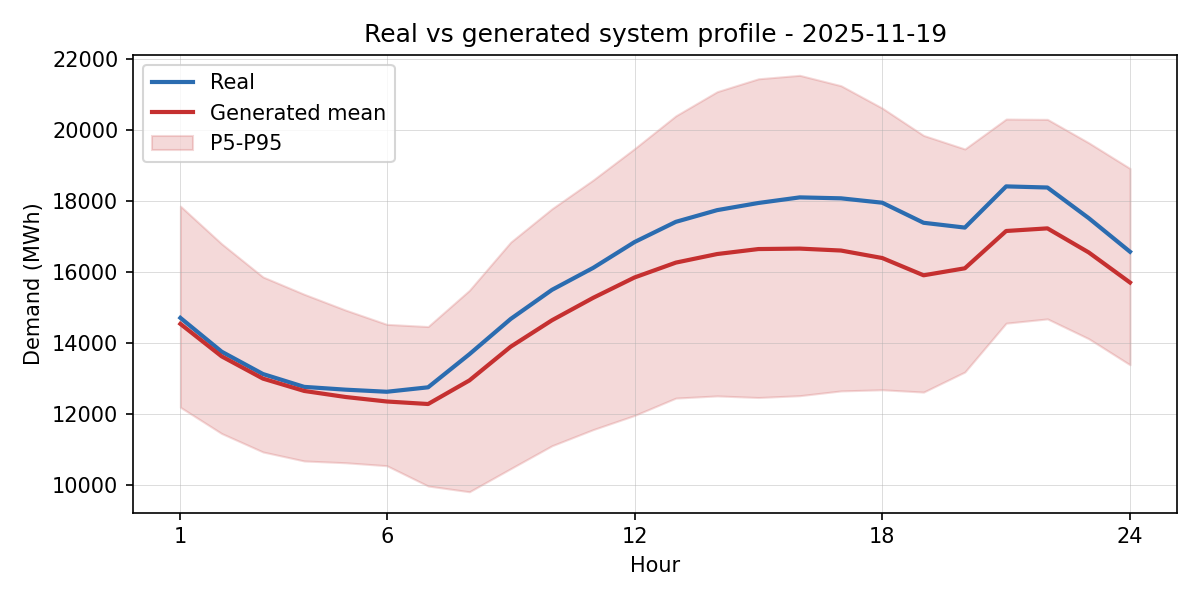

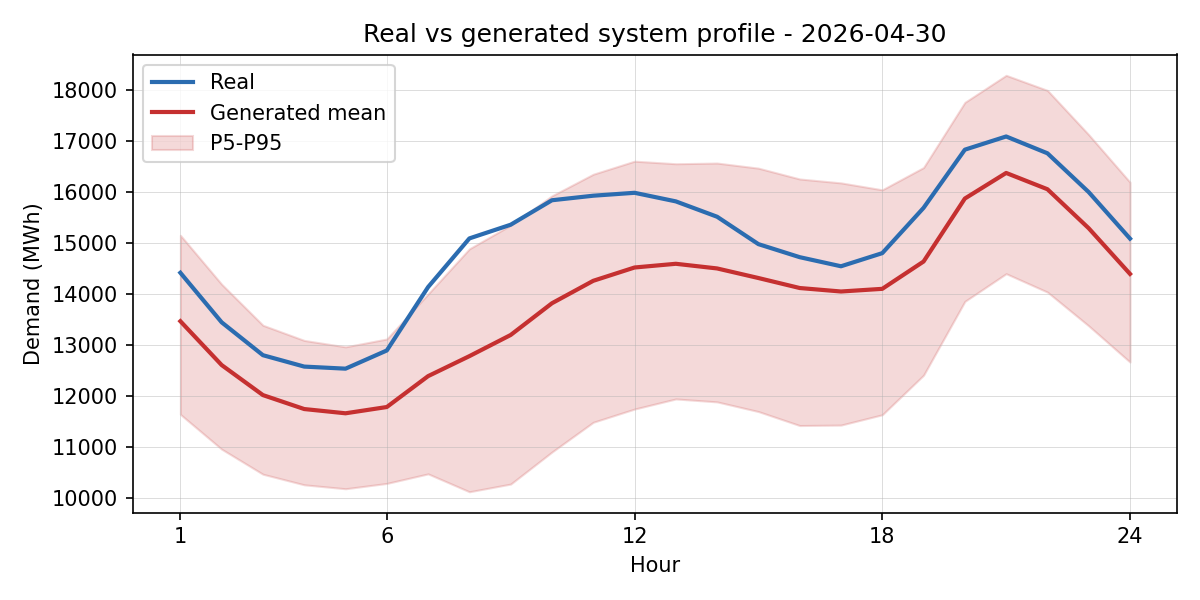

In [12]:
for plot_path in list_generation_plot_paths(output_dir, max_plots=4):
    display(Image(filename=str(plot_path)))

## Lectura del resultado

Este baseline es generativo y solo esta condicionado por calendario discreto. Si el coverage es bajo, la banda P5-P95 no alcanza a cubrir suficiente variabilidad real; si la sharpness es muy alta, el modelo cubre mas a costa de escenarios poco informativos. El valor de este modelo esta en dar una referencia simple para comparar despues contra modelos que usan informacion contextual mas rica.